# 04 · Straightening variables and passive corners

Discretising $g'$ as a piecewise constant makes $g_\Delta = a_jx+b_j$
affine on each cell. The characteristic equation $\dot p = -a_j p^2$ then
decouples, exactly as for $f = xu^2$. More is true: with $\sigma = \sqrt{|g_\Delta|}$
and $w = \sigma u$, each cell with $a_j\ne0$ carries Burgers' equation
$w_t + \tfrac{a_j}{2}(w^2)_\sigma = 0$. Hence

$$\sigma(\tau) = \sigma_0 + \tfrac12\alpha\kappa\tau,\qquad
  x(\tau) = x_0 + \kappa\tau\,(\sigma_0 + \tfrac14\alpha\kappa\tau),\qquad
  \alpha = \tfrac{d|g_\Delta|}{dx}.$$

Fronts are **straight lines in σ** and parabolas in x, and every event
time solves a linear equation. For a flat cell, sigma is constant and
cannot serve as a coordinate; the original x-coordinate gives constant
speed, and the displayed front formulas still apply.

In [1]:
# Use the local checkout if present; otherwise install from GitHub (needs the repository to be public).
import sys, subprocess, importlib.util
from pathlib import Path
local_src = next((p / "src" for p in (Path.cwd(), *Path.cwd().parents)
                  if (p / "src/hetfront/__init__.py").is_file()), None)
if local_src is not None:
    sys.path.insert(0, str(local_src))
elif importlib.util.find_spec("hetfront") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/parasuramv/heterogeneous-front-tracking"])
import numpy as np
import matplotlib.pyplot as plt
import hetfront
from hetfront import (HeteroFrontTracker, PeriodicHeteroFrontTracker, MultiplicativeFlux,
                      PiecewiseAffine, trajectory)
from hetfront.visualization import (observe_tracker, plot_spacetime, plot_profile,
                                    plot_heterogeneity, plot_diagnostics, plot_circle, overview)
%matplotlib inline
plt.rcParams["figure.dpi"] = 100
print("hetfront", hetfront.__version__, "from", "local checkout" if local_src else "installed package")

hetfront 0.1.0 from local checkout


## One front across many corners
Left: the path in $x$, curved. Right: $\sigma(t)$ along it, piecewise linear, with a kink only where the slope $\alpha$ of $|g_\Delta|$ changes, i.e. at corners.

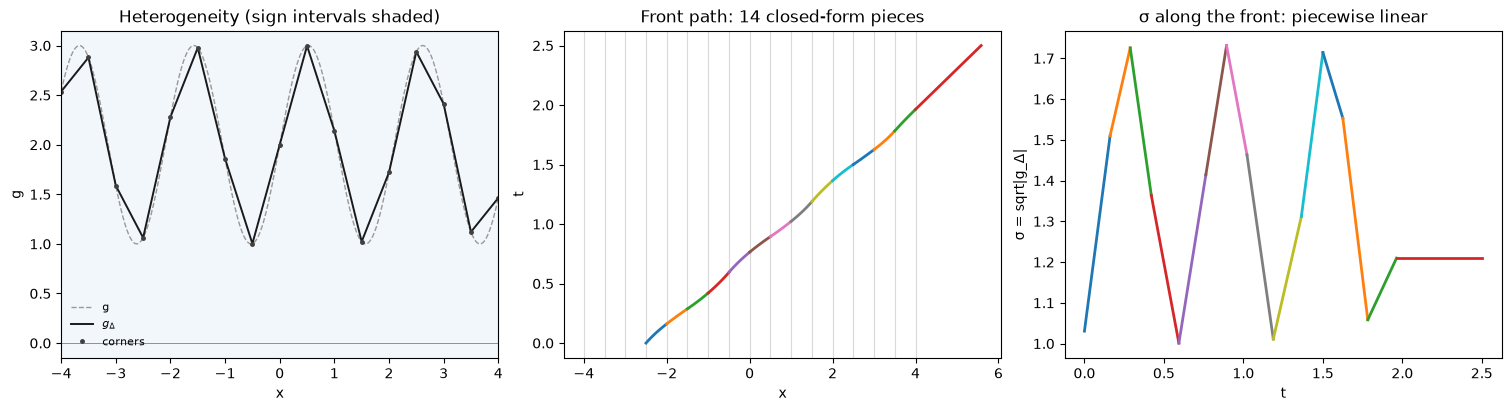

corner events: 13


In [2]:
g_exact = lambda x: 2 + np.sin(3 * x)
gd = PiecewiseAffine.from_function(g_exact, np.linspace(-4, 4, 17))
flux = MultiplicativeFlux(gd, 0.1)
tr = HeteroFrontTracker(flux, [-2.5], [30, 5]).run(2.5)
pieces = tr.pieces_until()
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
plot_heterogeneity(gd, (-4, 4), ax=axes[0], exact=g_exact)
for p in pieces:
    xs, ts = trajectory.sample_path(p.x0, p.s0, p.alpha, p.kappa, p.t0, p.t1, 40)
    axes[1].plot(xs, ts, lw=2)
    axes[2].plot(ts, [trajectory.sigma(p.s0, p.alpha, p.kappa, t - p.t0) for t in ts], lw=2)
for xn in gd.nodes:
    axes[1].axvline(xn, color="0.85", lw=0.8, zorder=0)
axes[1].set(xlabel="x", ylabel="t", title=f"Front path: {len(pieces)} closed-form pieces")
axes[2].set(xlabel="t", ylabel="σ = sqrt|g_Δ|", title="σ along the front: piecewise linear")
plt.show()
print("corner events:", tr.counts["corner"])

## Closed form versus numerical integration
Integrate the Rankine–Hugoniot ODE $\dot x = g_\Delta(x)\,(u_L+u_R)$ with RK4 and compare it with the closed-form position at the end.

In [3]:
def rk4(flux, kL, kR, x0, T, steps):
    speed = lambda x: flux.g(x) * (flux.u(kL, x) + flux.u(kR, x))
    x, h = x0, T / steps
    for _ in range(steps):
        k1 = speed(x); k2 = speed(x + h * k1 / 2); k3 = speed(x + h * k2 / 2); k4 = speed(x + h * k3)
        x += h * (k1 + 2 * k2 + 2 * k3 + k4) / 6
    return x
exact = tr.fronts[0].x(2.5)
for steps in (250, 1000, 4000):
    print(f"RK4 with {steps:5d} steps: |x_RK4 - x_closed| = {abs(rk4(flux, 30, 5, -2.5, 2.5, steps) - exact):.2e}")
print("RK4 converges to the closed form, but the kinks of the right-hand side at corners spoil its formal")
print("fourth order. The closed form needs no time steps at all.")

RK4 with   250 steps: |x_RK4 - x_closed| = 1.36e-06


RK4 with  1000 steps: |x_RK4 - x_closed| = 4.57e-07


RK4 with  4000 steps: |x_RK4 - x_closed| = 1.79e-08
RK4 converges to the closed form, but the kinks of the right-hand side at corners spoil its formal
fourth order. The closed form needs no time steps at all.


## Corners are passive

At a corner $g_\Delta$ is continuous, so $U[\theta]$ and the front speed
$\sigma\kappa$ are continuous too. Only the acceleration jumps. No wave is
emitted, and the front just switches to the next cell's law. With a
piecewise-*constant* $g$, by contrast, every node would be a
discontinuous-flux interface with its own Riemann solver.

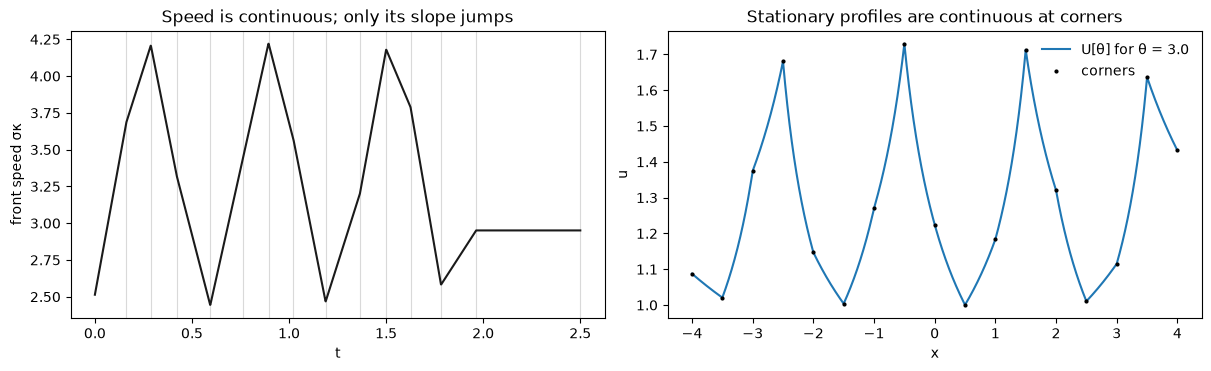

In [4]:
p0 = pieces[len(pieces) // 2]
t_corner = p0.t1
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), constrained_layout=True)
ts = np.linspace(0, 2.5, 2001)
def state(t):
    p = next(q for q in pieces if q.t0 <= t <= q.t1)
    return p, t - p.t0
speed = [state(t)[0].kappa * trajectory.sigma(state(t)[0].s0, state(t)[0].alpha, state(t)[0].kappa, state(t)[1]) for t in ts]
axes[0].plot(ts, speed, color="0.1")
for p in pieces:
    axes[0].axvline(p.t1, color="0.85", lw=0.8, zorder=0)
axes[0].set(xlabel="t", ylabel="front speed σκ", title="Speed is continuous; only its slope jumps")
x = np.linspace(-4, 4, 4001)
axes[1].plot(x, flux.u(np.full(x.shape, 30), x), label="U[θ] for θ = 3.0")
axes[1].plot(gd.nodes, flux.u(np.full(gd.nodes.shape, 30), gd.nodes), "k.", ms=4, label="corners")
axes[1].set(xlabel="x", ylabel="u", title="Stationary profiles are continuous at corners")
axes[1].legend(frameon=False)
plt.show()

## No division by α

The waiting times are

* reaching a node: $\tau = 2(x_n-x_0)/(\kappa(\sigma_0+\sigma_n))$;
* two fronts in one cell meeting: $\tau = 2(x_2-x_1)/((\sigma_1+\sigma_2)(\kappa_1-\kappa_2))$.

Both use $\sigma_2-\sigma_1 = \alpha(x_2-x_1)/(\sigma_1+\sigma_2)$, so
nothing divides by α. Flat cells ($\alpha=0$, constant $g$) are covered,
and the formulas are continuous as α → 0.

In [5]:
for alpha in (1.0, 1e-3, 1e-9, 0.0):
    s0 = 1.0
    x1 = 0.5; s1 = np.sqrt(s0**2 + alpha * x1)
    print(f"alpha = {alpha:7.0e}: travel time to x = 0.5 at kappa = 2: {trajectory.travel_time(0.0, s0, x1, s1, 2.0):.12f}")

alpha =   1e+00: travel time to x = 0.5 at kappa = 2: 0.224744871392
alpha =   1e-03: travel time to x = 0.5 at kappa = 2: 0.249968757810
alpha =   1e-09: travel time to x = 0.5 at kappa = 2: 0.249999999969
alpha =   0e+00: travel time to x = 0.5 at kappa = 2: 0.250000000000


## General powers $h(u)=|u|^p$

`MultiplicativeFlux(g, delta, power=p)` solves $u_t+(g|u|^p)_x=0$ for
any $p>1$. Write $q=1-1/p$, $m=p/(p-1)$ and $s(\theta)=\mathrm{sgn}(\theta)|\theta|^{1/p}$.
A front moves with $\dot x=|g_\Delta|^{1/p}K$, where
$K=(|\theta_R|-|\theta_L|)/(s_R-s_L)$ is the secant slope of $|r|^p$.
With $\sigma=|g_\Delta|^{q}$,

$$\dot\sigma = q\,\alpha K,\qquad
  x(\tau)=x_0+K\tau\,M\big(\sigma_0,\sigma(\tau)\big),\qquad
  M(\sigma_0,\sigma_1)=q\,\frac{\sigma_1^m-\sigma_0^m}{\sigma_1-\sigma_0}.$$

So fronts are **straight in σ for every p**. Every waiting time is
$\Delta x/(K\,M)$, and $M=(\sigma_0+\sigma_1)/2$ when $p=2$. Below, the same
data run with $p = 3/2, 2, 3$. Each σ-trace is piecewise linear, and the
closed form agrees with RK4 applied to the physical Rankine–Hugoniot ODE
$\dot x=[g|u|^p]/[u]$.

p = 1.5: K = 1.723991, corners  7, |x_RK4 - x_closed| = 5.8e-08


p =   2: K = 2.439158, corners  9, |x_RK4 - x_closed| = 6.3e-08


p =   3: K = 3.854759, corners 13, |x_RK4 - x_closed| = 3.8e-08


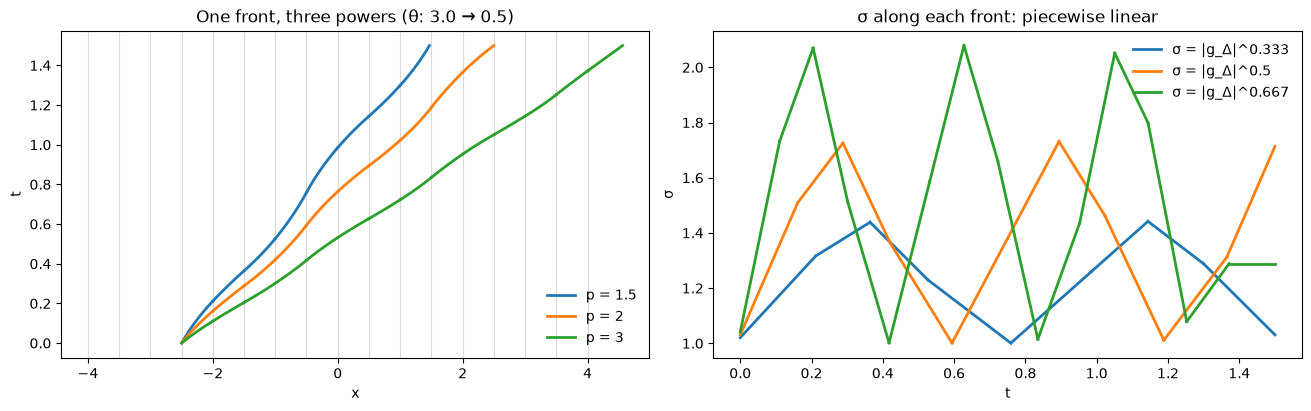

In [6]:
def rk4_power(flux, kL, kR, x0, T, steps):
    def speed(x):
        uL, uR = flux.u(kL, x), flux.u(kR, x)
        return flux.g(x) * (abs(uR) ** flux.power - abs(uL) ** flux.power) / (uR - uL)
    x, h = x0, T / steps
    for _ in range(steps):
        k1 = speed(x); k2 = speed(x + h * k1 / 2); k3 = speed(x + h * k2 / 2); k4 = speed(x + h * k3)
        x += h * (k1 + 2 * k2 + 2 * k3 + k4) / 6
    return x

fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
for p, colour in zip((1.5, 2.0, 3.0), ("C0", "C1", "C2")):
    fp = MultiplicativeFlux(gd, 0.1, power=p)
    tp = HeteroFrontTracker(fp, [-2.5], [30, 5]).run(1.5)
    for i, piece in enumerate(tp.pieces_until()):
        xs, ts = fp.law.sample_path(piece.x0, piece.s0, piece.alpha, piece.kappa, piece.t0, piece.t1, 40)
        sig = fp.law.sigma(piece.s0, piece.alpha, piece.kappa, ts - piece.t0)
        axes[0].plot(xs, ts, color=colour, lw=2, label=f"p = {p:g}" if i == 0 else None)
        axes[1].plot(ts, sig, color=colour, lw=2, label=f"σ = |g_Δ|^{fp.law.q:.3g}" if i == 0 else None)
    gap = abs(rk4_power(fp, 30, 5, -2.5, 1.5, 4000) - tp.fronts[0].x(1.5))
    print(f"p = {p:3g}: K = {fp.kappa(30, 5):.6f}, corners {tp.counts['corner']:2d}, |x_RK4 - x_closed| = {gap:.1e}")
for xn in gd.nodes:
    axes[0].axvline(xn, color="0.85", lw=0.8, zorder=0)
axes[0].set(xlabel="x", ylabel="t", title="One front, three powers (θ: 3.0 → 0.5)")
axes[1].set(xlabel="t", ylabel="σ", title="σ along each front: piecewise linear")
axes[0].legend(frameon=False); axes[1].legend(frameon=False)
plt.show()

### An exact solution for every p

For $g=x$, $\theta_L=0$, $\theta_R=-1$ and $x_0=1$: $K=-1$ and $\sigma=x^{q}=1-qt$,
so $x(t)=(1-qt)^m$. The shock reaches the zero, and is absorbed, at
$t=p/(p-1)$; for $p=2$ this is the manuscript's $(2-t)^2/4$ with $t=2$.
Since $p/(p-1)$ decreases in $p$, larger $p$ means earlier absorption. The
profiles beside the zero blow up like $|x|^{-1/p}$.

*Status.* These laws are elementary consequences of the Rankine–Hugoniot
condition. HetFT assumes a uniformly convex flux, which $|u|^p$ lacks globally for $p\ne2$. The
discrete shock/fan rule follows instead from an exact conjugacy: in
$X=\int|g_\Delta|^{-1/p}dx$ every front moves with $\dot X=K$, so the scheme
is homogeneous front tracking on each sign interval (derivation §5).
Convergence as $\delta,\Delta\to0$ has been measured for $p=3/2,2,3$
(notebook 07 and the convergence report); a continuum convergence proof
for general powers is still absent.

p = 1.5: max |x_tracker - (1 - qt)^m| = 2.8e-16
p = 2: max |x_tracker - (1 - qt)^m| = 2.2e-16
p = 3: max |x_tracker - (1 - qt)^m| = 2.8e-16


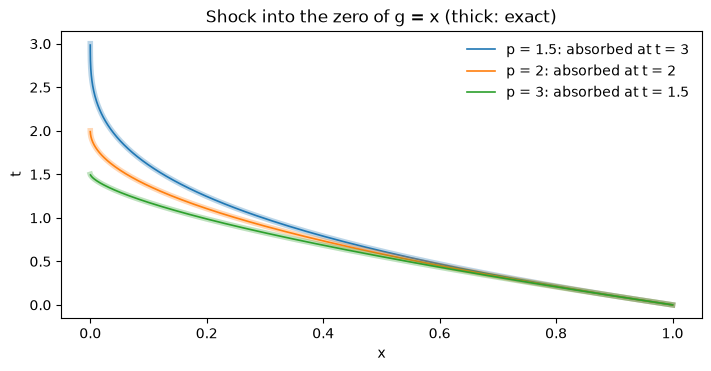

In [7]:
xu_g = PiecewiseAffine([-1, 1], [-1, 1], extend="affine")
fig, ax = plt.subplots(figsize=(7, 3.6), constrained_layout=True)
for p, colour in zip((1.5, 2.0, 3.0), ("C0", "C1", "C2")):
    fp = MultiplicativeFlux(xu_g, 1.0, power=p)
    q, m = fp.law.q, fp.law.m
    arrival = p / (p - 1)
    tp = HeteroFrontTracker(fp, [1.0], [0, -1])
    ts = np.linspace(0, arrival, 200)
    ax.plot((1 - q * ts) ** m, ts, color=colour, lw=4, alpha=0.3)
    closed = []
    for t in ts[:-1]:
        tp.run(t)
        closed.append(tp.fronts[0].x(t))
    ax.plot(closed, ts[:-1], color=colour, lw=1.2, label=f"p = {p:g}: absorbed at t = {arrival:g}")
    print(f"p = {p:g}: max |x_tracker - (1 - qt)^m| = {np.max(np.abs(np.array(closed) - (1 - q * ts[:-1]) ** m)):.1e}")
ax.set(xlabel="x", ylabel="t", title="Shock into the zero of g = x (thick: exact)")
ax.legend(frameon=False)
plt.show()